# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [1]:
import pandas as pd
import numpy as np

In [ ]:
def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))



#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [0]:
def sse(y_true, y_pred):
    return np.sum((np.asarray(y_true) - np.asarray(y_pred)) ** 2)

def mse(y_true, y_pred):
    return sse(y_true, y_pred) / len(y_true)


#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [0]:
def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))



#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [0]:
def mape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    nonzero = y_true != 0
    return np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100



#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [0]:
def r2(y_true, y_pred):
    y_true = np.asarray(y_true)
    sst = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - sse(y_true, y_pred) / sst



### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [9]:
advertising = pd.read_csv('advertising.csv')
advertising = advertising.drop(columns=['Unnamed: 0'], errors='ignore')
advertising.head()


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [10]:
X = advertising[['TV', 'Radio', 'Newspaper']]
y = advertising['Sales']
print('Features:', X.shape)
print('Target:', y.shape)
advertising.describe()


Features: (200, 3)
Target: (200,)


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [11]:
corr = advertising.corr(numeric_only=True)
display(corr)


,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


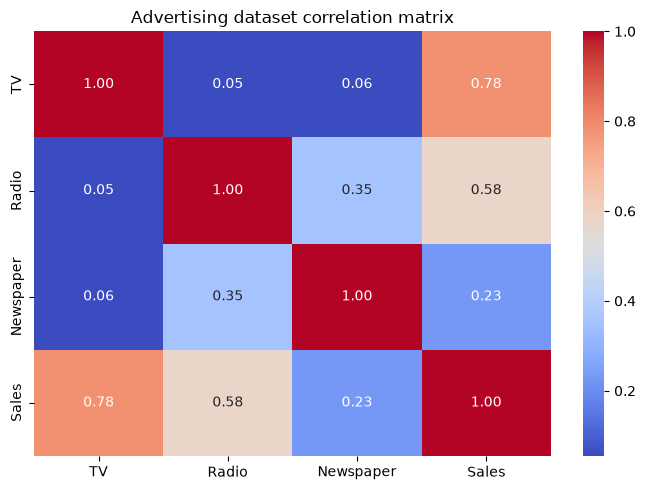

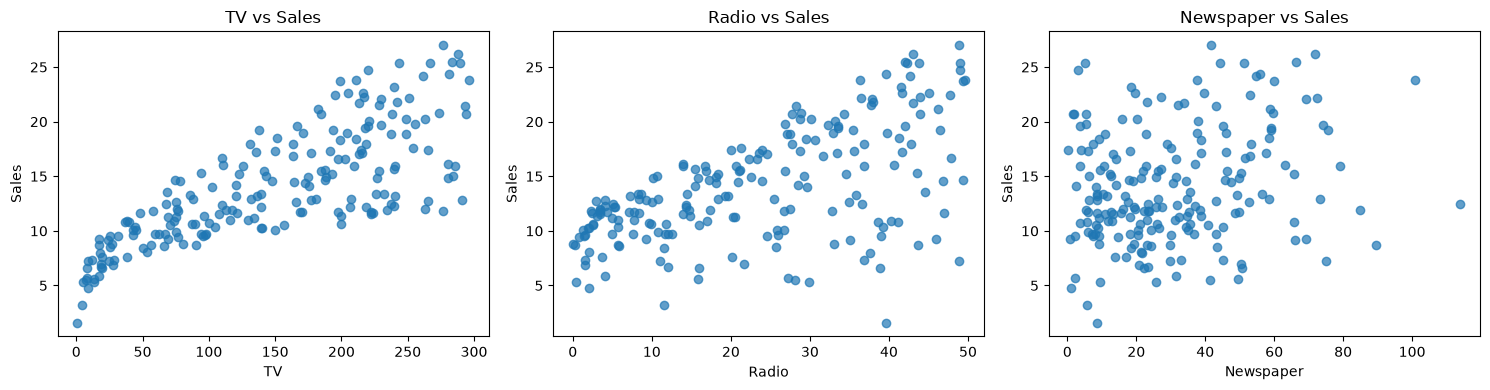

Observation: Sales has the strongest positive correlation with TV advertising,
followed by Radio. Newspaper has a much weaker positive correlation with Sales.


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Advertising dataset correlation matrix')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ['TV', 'Radio', 'Newspaper']):
    ax.scatter(advertising[feature], y, alpha=0.7)
    ax.set_xlabel(feature)
    ax.set_ylabel('Sales')
    ax.set_title(f'{feature} vs Sales')
plt.tight_layout()
plt.show()

print('Observation: Sales has the strongest positive correlation with TV advertising,')
print('followed by Radio. Newspaper has a much weaker positive correlation with Sales.')


#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [23]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape, X_test_scaled.shape)


(134, 3) (66, 3)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [24]:

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_pred = linear_model.predict(X_test_scaled)
print('Intercept (b0):', linear_model.intercept_)
print('Coefficients (TV, Radio, Newspaper):', linear_model.coef_)



Intercept (b0): 14.022388059701495
Coefficients (TV, Radio, Newspaper): [ 3.9675339   2.88155345 -0.07344038]


,Actual,Predicted
0,22.1,20.488582
1,13.2,15.296503
2,7.3,10.552781
3,20.2,20.025001
4,12.8,12.843469
5,11.3,10.278666
6,8.7,11.938648
7,15.2,15.114197
8,11.8,11.591867
9,10.1,10.019775


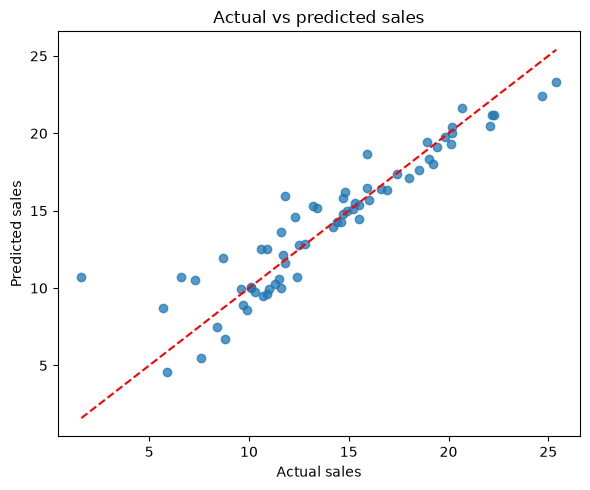

In [25]:
results = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
display(results.head(10))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.75)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, 'r--')
plt.xlabel('Actual sales')
plt.ylabel('Predicted sales')
plt.title('Actual vs predicted sales')
plt.tight_layout()
plt.show()


#### 2.5 Evaluate created model with above functions

In [ ]:
print(f'MAE:  {mae(y_test, y_pred):.4f}')


MAE:  1.2415

Statistical interpretation:
Each coefficient estimates the change in Sales for a one-standard-deviation
increase in the corresponding advertising budget, holding the other features constant.
The intercept is the predicted Sales when all scaled features equal zero.


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [34]:
from sklearn.pipeline import make_pipeline
cv_model = make_pipeline(StandardScaler(), LinearRegression())
cv_scores = cross_val_score(cv_model, X, y, cv=KFold(n_splits=10, shuffle=True, random_state=17), scoring='r2')
print('R² scores:', np.round(cv_scores, 4))
print('Mean 10-fold R²:', cv_scores.mean())


R² scores: [0.8889 0.7756 0.8174 0.9468 0.8797 0.9271 0.799  0.8937 0.9084 0.9347]
Mean 10-fold R²: 0.877112599900056


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [ ]:
X_reduced = advertising[['TV', 'Radio']]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reduced, y, test_size=0.33, random_state=17
)
reduced_scaler = StandardScaler()
Xr_train_scaled = reduced_scaler.fit_transform(Xr_train)
Xr_test_scaled = reduced_scaler.transform(Xr_test)

reduced_model = LinearRegression()
reduced_model.fit(Xr_train_scaled, yr_train)
y_pred_reduced = reduced_model.predict(Xr_test_scaled)

print('Reduced model coefficients (TV, Radio):', reduced_model.coef_)


Reduced model coefficients (TV, Radio): [3.95954712 2.85961481]


In [41]:
comparison = pd.DataFrame({
    'Model': ['Full (TV, Radio, Newspaper)', 'Reduced (TV, Radio)'],
    'MAE': [mae(y_test, y_pred), mae(yr_test, y_pred_reduced)],

})
display(comparison)


,Model,MAE
0,"Full (TV, Radio, Newspaper)",1.241490
1,"Reduced (TV, Radio)",1.242362


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [ ]:
lasso = make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=10000))
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)
print('Lasso coefficients:', lasso.named_steps['lasso'].coef_)


Lasso coefficients: [3.0619592  1.96202634 0.        ]


#### 3.2 Ridge regression

In [45]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)
print('Ridge coefficients:', ridge.named_steps['ridge'].coef_)


Ridge coefficients: [ 3.93899368  2.85996406 -0.06218255]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [47]:
elastic_net = make_pipeline(StandardScaler(), ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000))
elastic_net.fit(X_train, y_train)
elastic_pred = elastic_net.predict(X_test)
print('Elastic Net coefficients:', elastic_net.named_steps['elasticnet'].coef_)


Elastic Net coefficients: [2.39397459 1.68907463 0.01489489]


#### 3.4 Make conclusions

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

#### 2.4 Fit logistic regression model, generate predictions

#### 2.5 Create a confusion matrix and evaluate created model with above functions

#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

#### 3.2 Evaluate created model with above functions

#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

#### 3.5 Make conclusions